# Gel point and clot onset detection

A working pipeline for detecting when an evolving fluid stops being a liquid, extracted from a
research notebook of 100 cells and reduced to what survived contact with real data.

**What this does.** Takes a time series of rheological measurements, checks whether the data can
support a detection at all, runs only the detectors the data supports, and reports each answer
with a verdict on whether it is a measurement or an artefact.

**What it deliberately does not do.** It does not always return an answer. Where the data cannot
support a detection it says so and returns nothing, because a detector that always answers will
pass a bench test and fail in use.

**How to use it.** Edit Section 2, which is the only part that needs changing. Everything after
it is fixed. A worked example on a public dataset is included so the notebook can be verified
before it is pointed at anything new.

**What the detectors were scored against.** On a synthetic material with a known gel point, the
five detectors that time the transition agree within 34.9 s of a 500 s answer. On real clotting
blood, the persistent crossover matched a published clot time to 2.5 percent. On 24 trauma
patients, two onset detectors fired before the clinical clot time in every patient and agreed
with each other to 5.1 s.

**One warning that matters more than the rest.** On human blood treated so that it cannot
coagulate, every detector that works from a single channel fired anyway, between 52 and 100
percent of the time. Sheared blood rebuilds structure over 10 to 30 s, which overlaps the range
in which real clots form. A detection from one channel is not evidence of clotting. Section 7
covers this.

## 1  Setup

Requires numpy, pandas, scipy and matplotlib. The changepoint detectors additionally require
`ruptures`; if it is absent the notebook runs without them and says so.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import ruptures
    CHANGEPOINT_AVAILABLE = True
except ImportError:
    CHANGEPOINT_AVAILABLE = False

CHANGEPOINT_PENALTY = 3.0
CHANGEPOINT_MINIMUM_SIZE = 3
CUSUM_BASELINE_FRACTION = 0.2
CUSUM_THRESHOLD_MULTIPLIER = 5.0

CROSSOVER_CREDIBILITY_FACTOR = 5.0
MINIMUM_POINTS_BEFORE_TRANSITION = 12
MINIMUM_FREQUENCIES_FOR_AGREEMENT = 3

COLOUR_PRIMARY = "#1f77b4"
COLOUR_SECONDARY = "#d62728"
COLOUR_NEUTRAL = "#7f7f7f"

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("changepoint detectors available:", CHANGEPOINT_AVAILABLE)

if not CHANGEPOINT_AVAILABLE:
    print()
    print("  install ruptures to enable the changepoint detectors")
    print("  the crossover and growth rate detectors run without it")

numpy 2.4.4
pandas 3.0.2
changepoint detectors available: True


## 2  Your data

This is the only section to edit.

Fill in `load_measurement` so that it returns one dictionary per record. Everything downstream
depends only on the keys, not on the file format.

**Required.** `record_name`, and `time_seconds` as a strictly increasing array.

**Then one of two cases.**

If the instrument reports a storage and a loss modulus, supply `storage_modulus` and
`loss_modulus`, both in pascals, and `probe_frequency` in rad/s. This is the two channel case
and a gel point is available.

If several frequencies are measured at each instant, supply `frequency_spectra` instead: a list
with one entry per time point, each holding `angular_frequency` and `complex_modulus` arrays.
This is the multi-frequency case and the physical definition of a gel point becomes available.

If the instrument reports a single quantity that rises as the material stiffens, an amplitude, a
pressure or a stiffness, supply it as `single_channel` with its units in `channel_units`. This
is the one channel case and only an onset is available, never a gel point.

**Strongly recommended.** `noise_floor_pascals`, the smallest modulus the instrument can resolve.
This is not a percentage noise figure. A percentage says how well a signal is measured; the
floor says whether there is a signal at all. Without it the crossover detector cannot reject
crossings that occur in the noise, and Section 4 will say so.

In [2]:
EXAMPLE_DATA_DIRECTORY = "data"


def load_measurement():
    """
    Returning the records to analyse.

    Replace the body of this function with your own loader. The worked example below reads a
    public dataset of clotting sheep blood so the notebook can be verified before being
    pointed at new data.

    Each record is a dictionary. See Section 2 for the keys.
    """
    example_path = os.path.join(EXAMPLE_DATA_DIRECTORY, "app_sheepblood_clot.xlsx")

    if not os.path.isfile(example_path):
        print("  example data not found, returning nothing")
        print("  replace this function with your own loader")
        return []

    example_table = pd.read_excel(example_path, sheet_name="Figure 2", header=None)

    column_groups = [("natural", 0, 1, 2), ("xHA", 3, 4, 5), ("oHA", 6, 7, 8)]

    records = []

    for material_name, time_column, storage_column, loss_column in column_groups:

        time_values = pd.to_numeric(example_table[time_column][6:],
                                    errors="coerce").values
        storage_values = pd.to_numeric(example_table[storage_column][6:],
                                       errors="coerce").values
        loss_values = pd.to_numeric(example_table[loss_column][6:],
                                    errors="coerce").values

        usable = (np.isfinite(time_values) & np.isfinite(storage_values)
                  & np.isfinite(loss_values))

        time_values = time_values[usable]
        storage_values = storage_values[usable]
        loss_values = loss_values[usable]

        # This file stacks two experiments in one column: a time sweep, then an
        # amplitude sweep whose axis restarts. Section 3 detects that. Here the
        # loader acts on it and keeps only the first block, which is the time sweep.
        restart_indices = []

        for point_index in range(len(time_values) - 1):
            if time_values[point_index + 1] < 0.5 * time_values[point_index]:
                restart_indices.append(point_index)

        if len(restart_indices) > 0:
            keep_until = restart_indices[0] + 1
            time_values = time_values[:keep_until]
            storage_values = storage_values[:keep_until]
            loss_values = loss_values[:keep_until]

        records.append({
            "record_name": material_name,
            "time_seconds": time_values,
            "storage_modulus": storage_values,
            "loss_modulus": loss_values,
            "probe_frequency": 2.0 * np.pi,
            "noise_floor_pascals": None,
        })

    return records


measurement_records = load_measurement()

print("records loaded:", len(measurement_records))

for record in measurement_records:
    print("  " + str(record["record_name"]).ljust(16)
          + str(len(record["time_seconds"])).rjust(6) + " points")

records loaded: 3
  natural             76 points
  xHA                 76 points
  oHA                 76 points


## 3  Data audit

Run before any analysis. Four checks, each of which caught a real error in the research
notebook and would have produced a wrong number if it had not.

**Stacked records.** Four of thirteen datasets held two experiments in one column with no
separator, so the time axis restarts partway down. Read as a single record they produce a
fit to a curve that does not exist.

**Duplicated records.** Three datasets contained blocks identical to nine significant figures,
which is copying rather than repeated measurement. Averaging across them weights those
conditions twice.

**Coverage before the transition.** A detector needs measurements taken while the material is
still liquid. One clotting sample in the research data had none, because the clot formed before
recording started.

**Coverage after the transition.** A record that stops at the transition cannot distinguish the
material changing from the experiment ending.

In [3]:
def find_restarts(time_values, restart_ratio=0.5):
    """
    Finding where a time axis starts again, which means two experiments are stacked in one
    column.

    Cutting only where the next value is less than half the current one, since a small step
    backwards is an overlap between acquisition segments rather than a new record.
    """
    restart_indices = []

    for point_index in range(len(time_values) - 1):
        if time_values[point_index + 1] < restart_ratio * time_values[point_index]:
            restart_indices.append(point_index)

    return restart_indices


def audit_record(record):
    """
    Checking one record for the faults that produced wrong numbers in the research notebook.

    Returning a list of findings, empty when the record is clean.
    """
    findings = []

    time_values = np.asarray(record["time_seconds"], dtype=float)

    if len(time_values) < 5:
        findings.append("fewer than five points, nothing can be run")
        return findings

    restart_indices = find_restarts(time_values)

    if len(restart_indices) > 0:
        findings.append("time axis restarts " + str(len(restart_indices))
                        + " time(s): two experiments may be stacked in one column")

    if not np.all(np.diff(time_values) > 0):
        findings.append("time is not strictly increasing")

    sampling_intervals = np.diff(time_values)
    interval_spread = float(np.std(sampling_intervals) / np.mean(sampling_intervals))

    if interval_spread > 0.5:
        findings.append("sampling interval varies by more than half its own size")

    if "storage_modulus" in record and record["storage_modulus"] is not None:

        storage_values = np.asarray(record["storage_modulus"], dtype=float)

        non_positive = int(np.sum(storage_values <= 0.0))

        if non_positive > 0:
            findings.append(str(non_positive) + " storage modulus values are zero or "
                            + "negative, which usually means the noise floor")

    if record.get("noise_floor_pascals") is None:
        findings.append("no instrument noise floor supplied, so crossings in the noise "
                        + "cannot be rejected")

    return findings


def find_duplicate_records(records):
    """
    Finding records whose measured series is identical to another already seen.
    """
    duplicate_pairs = []

    for first_index in range(len(records)):
        for second_index in range(first_index + 1, len(records)):

            first_record = records[first_index]
            second_record = records[second_index]

            first_values = first_record.get("storage_modulus")
            second_values = second_record.get("storage_modulus")

            if first_values is None:
                first_values = first_record.get("single_channel")
                second_values = second_record.get("single_channel")

            if first_values is None or second_values is None:
                continue

            shortest = min(len(first_values), len(second_values))

            if shortest < 10:
                continue

            if np.allclose(np.asarray(first_values[:shortest], dtype=float),
                           np.asarray(second_values[:shortest], dtype=float),
                           rtol=1e-9):
                duplicate_pairs.append((first_record["record_name"],
                                        second_record["record_name"]))

    return duplicate_pairs


print("Data audit")
print()

clean_count = 0

for record in measurement_records:

    findings = audit_record(record)

    if len(findings) == 0:
        clean_count = clean_count + 1
        print("  " + str(record["record_name"]).ljust(18) + "clean")
    else:
        print("  " + str(record["record_name"]).ljust(18) + str(len(findings))
              + " finding(s)")
        for finding_text in findings:
            print("      " + finding_text)

duplicate_pairs = find_duplicate_records(measurement_records)

print()

if len(duplicate_pairs) == 0:
    print("  no duplicated records")
else:
    print("  " + str(len(duplicate_pairs)) + " duplicated pair(s) found:")
    for first_name, second_name in duplicate_pairs:
        print("      " + str(first_name) + " and " + str(second_name))

print()
print("  " + str(clean_count) + " of " + str(len(measurement_records)) + " records clean")
print()
print("  a finding is not necessarily fatal. It means the record needs a decision before")
print("  the numbers below can be trusted")

Data audit

  natural           1 finding(s)
      no instrument noise floor supplied, so crossings in the noise cannot be rejected
  xHA               1 finding(s)
      no instrument noise floor supplied, so crossings in the noise cannot be rejected
  oHA               1 finding(s)
      no instrument noise floor supplied, so crossings in the noise cannot be rejected

  no duplicated records

  0 of 3 records clean

  a finding is not necessarily fatal. It means the record needs a decision before
  the numbers below can be trusted


## 4  What each record can support

Four questions about the measurement, answered before anything runs. None of them mentions the
material, which is what makes them transferable.

The rule is deliberately conservative. On the research data it refused two records that did in
fact produce usable answers, and it never licensed one that failed structurally. Over-refusing
is the safe direction for a medical device.

**One caution.** The threshold of a dozen points before the transition was derived on synthetic
data and does not order the errors on real data. Four points gave 17 percent error on one
sample and thirty gave 75 percent on another. It is retained as a guide, not as a predictor of
accuracy.

In [4]:
def describe_record_capability(record):
    """
    Deciding what kind of answer a record can support, before any analysis.

    Taking only properties of the measurement, since in the research notebook every failure
    traced to one of these four and none to the material.
    """
    channel_count = 0
    frequency_count = 0

    if record.get("frequency_spectra") is not None:
        channel_count = 2
        frequency_count = len(record["frequency_spectra"][0]["angular_frequency"])
    elif record.get("storage_modulus") is not None:
        channel_count = 2
        frequency_count = 1
    elif record.get("single_channel") is not None:
        channel_count = 1
        frequency_count = 1

    if channel_count == 0:
        return {"available": "nothing", "reason": "no recognised measurement columns",
                "channel_count": 0, "frequency_count": 0}

    if channel_count < 2:
        return {"available": "an onset only",
                "reason": "one channel gives no tan delta, so no gel point of any kind",
                "channel_count": 1, "frequency_count": 1}

    if frequency_count >= MINIMUM_FREQUENCIES_FOR_AGREEMENT:
        return {"available": "a gel point, by frequency agreement",
                "reason": "several frequencies and both moduli, the full condition",
                "channel_count": 2, "frequency_count": frequency_count}

    return {"available": "a gel point, by persistent crossover",
            "reason": "one frequency, so the crossover is the only gel point available",
            "channel_count": 2, "frequency_count": 1}


print("What each record can support")
print()
print("  record".ljust(20) + "channels".rjust(10) + "frequencies".rjust(13)
      + "   what is available")

for record in measurement_records:

    capability = describe_record_capability(record)
    record["capability"] = capability

    print("  " + str(record["record_name"]).ljust(18)
          + str(capability["channel_count"]).rjust(10)
          + str(capability["frequency_count"]).rjust(13)
          + "   " + capability["available"])

print()

for record in measurement_records:
    print("  " + str(record["record_name"]).ljust(18)
          + record["capability"]["reason"])

print()
print("  a gel point is a change in what kind of material is present. An onset is when a")
print("  measured quantity starts moving. On 24 trauma patients those separated by a median")
print("  of 15 seconds and by 290 seconds on one patient, so they are not interchangeable")

What each record can support

  record              channels  frequencies   what is available
  natural                    2            1   a gel point, by persistent crossover
  xHA                        2            1   a gel point, by persistent crossover
  oHA                        2            1   a gel point, by persistent crossover

  natural           one frequency, so the crossover is the only gel point available
  xHA               one frequency, so the crossover is the only gel point available
  oHA               one frequency, so the crossover is the only gel point available

  a gel point is a change in what kind of material is present. An onset is when a
  measured quantity starts moving. On 24 trauma patients those separated by a median
  of 15 seconds and by 290 seconds on one patient, so they are not interchangeable


## 5  Detectors

Three detectors, taken unchanged from the research notebook.

**Winter and Chambon frequency agreement.** The physical definition: at the gel point tan delta
stops depending on frequency. Requires several frequencies measured within one snapshot. It
refuses a minimum falling at either end of the record, because an experiment stopping is not a
material changing.

**Persistent crossover.** The moment tan delta reaches one and stays there. Three amendments
were required before it worked on real data: it takes an instrument noise floor and refuses
crossings below it, it refuses a crossing that does not hold to the end of the record, and its
answer is checked against the measured range. The second amendment exists because one clotting
sample crossed at 34 s, came apart, and crossed again at 114 s, with storage moduli of 1.336
and 1.374 Pa at the two crossings, so no threshold could separate them.

**Maximum growth rate.** The fastest fractional change. This works from a single channel and
returns an onset rather than a gel point. On the trauma cohort it fired before the clinical
time in 24 of 24 patients.

The changepoint detectors are included when `ruptures` is available. PELT agreed with the
growth rate to 5.1 s on the trauma cohort; the kernel and CUSUM variants failed on every real
blood dataset and are reported for completeness rather than recommended.

In [5]:
def compute_tan_delta(storage_modulus_values, loss_modulus_values):
    """
    Computing tan delta, the ratio of loss modulus to storage modulus.

    Returning a missing value wherever the storage modulus is zero, negative or not
    finite, which happens when the measurement sits below the instrument noise floor.
    """
    storage_array = np.asarray(storage_modulus_values, dtype=float)
    loss_array = np.asarray(loss_modulus_values, dtype=float)

    tan_delta_array = np.full(storage_array.shape, np.nan)

    valid_mask = (storage_array > 0.0) & np.isfinite(storage_array) & np.isfinite(loss_array)
    tan_delta_array[valid_mask] = loss_array[valid_mask] / storage_array[valid_mask]

    return tan_delta_array


def detect_gel_time_by_persistent_crossover(snapshot_time_array, storage_modulus_series,
                                            loss_modulus_series, noise_floor,
                                            credibility_factor=5.0):
    """
    Detecting a gel time from the crossover, requiring the crossing to hold afterwards.

    Cell 62 refused a crossing while the moduli sat below the instrument floor. That is not
    enough on blood, where a record can cross into solid behaviour, fall back to liquid and
    cross again later at almost the same modulus, so no floor can tell the two apart.

    Requiring instead that tan delta stays below one for the remainder of the record, which
    is the difference between a material that has gelled and one that briefly looked as
    though it had.

    Interpolating between the two samples either side of the crossing, and returning a
    missing value when no crossing holds.
    """
    time_array = np.asarray(snapshot_time_array, dtype=float)
    storage_array = np.asarray(storage_modulus_series, dtype=float)
    loss_array = np.asarray(loss_modulus_series, dtype=float)

    tan_delta_series = loss_array / np.maximum(np.abs(storage_array), 1e-30)

    for point_index in range(len(tan_delta_series) - 1):

        if tan_delta_series[point_index] <= 1.0:
            continue
        if tan_delta_series[point_index + 1] > 1.0:
            continue
        if storage_array[point_index + 1] < credibility_factor * noise_floor:
            continue

        if not np.all(tan_delta_series[point_index + 1:] <= 1.0):
            continue

        tan_delta_span = (tan_delta_series[point_index]
                          - tan_delta_series[point_index + 1])

        if tan_delta_span > 0.0:
            crossing_fraction = (tan_delta_series[point_index] - 1.0) / tan_delta_span
        else:
            crossing_fraction = 0.0

        return (time_array[point_index]
                + crossing_fraction * (time_array[point_index + 1]
                                       - time_array[point_index]))

    return np.nan


def judge_estimate_against_record(estimate_value, snapshot_time_array):
    """
    Deciding whether a detector's answer is a measurement or an artefact of where the
    record happens to start and stop.

    Rejecting an answer that falls outside the measured range, since nothing was observed
    there, and flagging one that lands on the first or last sample, since Cell 65 showed
    that is usually the experiment ending rather than the material changing.

    Returning a short verdict.
    """
    if not np.isfinite(estimate_value):
        return "no answer"

    time_array = np.asarray(snapshot_time_array, dtype=float)
    sampling_interval = float(np.median(np.diff(time_array)))

    if estimate_value < time_array.min() or estimate_value > time_array.max():
        return "outside the record"

    if abs(estimate_value - time_array.min()) < 0.5 * sampling_interval:
        return "at the first sample"

    if abs(estimate_value - time_array.max()) < 0.5 * sampling_interval:
        return "at the last sample"

    return "usable"

In [6]:
def detect_onset_by_growth_rate(time_values, signal_values):
    """
    Finding when a signal was growing fastest in fractional terms.

    Working on the logarithm so the answer is where the signal changed most relative to its
    own size, which is early in a transition rather than at the end where it adds the most
    absolute units.

    This works from a single channel and returns an onset, not a gel point.
    """
    time_array = np.asarray(time_values, dtype=float)
    signal_array = np.asarray(signal_values, dtype=float)

    positive_mask = signal_array > 0.0

    if int(np.sum(positive_mask)) < 15:
        return np.nan

    usable_time = time_array[positive_mask]
    usable_signal = signal_array[positive_mask]

    growth_rate = np.gradient(np.log(usable_signal), usable_time)

    peak_index = int(np.argmax(growth_rate))

    if peak_index <= 0 or peak_index >= len(usable_time) - 1:
        return float(usable_time[peak_index])

    left_value = growth_rate[peak_index - 1]
    centre_value = growth_rate[peak_index]
    right_value = growth_rate[peak_index + 1]

    denominator = left_value - 2.0 * centre_value + right_value

    if abs(denominator) < 1e-30:
        return float(usable_time[peak_index])

    offset = 0.5 * (left_value - right_value) / denominator

    spacing = usable_time[peak_index + 1] - usable_time[peak_index]

    return float(usable_time[peak_index] + offset * spacing)


def detect_gel_time_by_frequency_agreement(snapshot_times, frequency_spectra):
    """
    Finding the gel point by the physical definition.

    At the gel point tan delta is the same at every frequency, so the spread of tan delta
    across frequency passes through a minimum. Working on the logarithm so the spread is
    relative rather than absolute.

    Refusing a minimum that falls at the first or last usable snapshot, since an experiment
    ending is not a material changing.
    """
    spread_values = []
    usable_times = []

    for snapshot_index in range(len(frequency_spectra)):

        spectrum = frequency_spectra[snapshot_index]

        storage_values = np.asarray(spectrum["complex_modulus"]).real
        loss_values = np.asarray(spectrum["complex_modulus"]).imag

        tan_delta_values = compute_tan_delta(storage_values, loss_values)

        finite_values = tan_delta_values[np.isfinite(tan_delta_values)]
        finite_values = finite_values[finite_values > 0.0]

        if len(finite_values) < MINIMUM_FREQUENCIES_FOR_AGREEMENT:
            continue

        spread_values.append(float(np.std(np.log(finite_values))))
        usable_times.append(float(snapshot_times[snapshot_index]))

    if len(spread_values) < 3:
        return np.nan, "fewer than three usable snapshots"

    spread_values = np.array(spread_values)
    usable_times = np.array(usable_times)

    minimum_index = int(np.argmin(spread_values))

    if minimum_index == 0 or minimum_index == len(spread_values) - 1:
        return np.nan, "minimum falls at the edge of the record, so it is refused"

    return float(usable_times[minimum_index]), "interior minimum"


print("detectors defined")
print()
print("  frequency agreement    the physical definition, needs several frequencies")
print("  persistent crossover   one frequency, both moduli, three amendments applied")
print("  growth rate            one channel, returns an onset rather than a gel point")

detectors defined

  frequency agreement    the physical definition, needs several frequencies
  persistent crossover   one frequency, both moduli, three amendments applied
  growth rate            one channel, returns an onset rather than a gel point


## 6  Results

Each answer is checked before it is reported. An estimate outside the measured range describes
something nobody watched. An estimate landing on the first or last sample is the record ending
rather than the material changing. Both are rejected rather than quoted.

In [7]:
def judge_estimate_against_record(estimate_value, time_values):
    """
    Deciding whether an answer is a measurement or an artefact of where the record starts
    and stops.
    """
    if not np.isfinite(estimate_value):
        return "no answer"

    time_array = np.asarray(time_values, dtype=float)
    sampling_interval = float(np.median(np.diff(time_array)))

    if estimate_value < time_array.min() or estimate_value > time_array.max():
        return "outside the record"

    if abs(estimate_value - time_array.min()) < 0.5 * sampling_interval:
        return "at the first sample"

    if abs(estimate_value - time_array.max()) < 0.5 * sampling_interval:
        return "at the last sample"

    return "usable"


def analyse_record(record):
    """
    Running every detector the record can support, and judging each answer.
    """
    time_values = np.asarray(record["time_seconds"], dtype=float)

    noise_floor = record.get("noise_floor_pascals")

    if noise_floor is None:
        noise_floor = 0.0

    results = {}

    if record.get("frequency_spectra") is not None:

        estimate, reason = detect_gel_time_by_frequency_agreement(
            time_values, record["frequency_spectra"])

        results["frequency agreement"] = {"estimate": estimate, "note": reason,
                                          "kind": "gel point"}

    if record.get("storage_modulus") is not None:

        estimate = detect_gel_time_by_persistent_crossover(
            time_values, np.asarray(record["storage_modulus"], dtype=float),
            np.asarray(record["loss_modulus"], dtype=float), noise_floor,
            CROSSOVER_CREDIBILITY_FACTOR)

        results["persistent crossover"] = {"estimate": estimate, "note": "",
                                           "kind": "gel point"}

        signal_values = np.asarray(record["storage_modulus"], dtype=float)
    else:
        signal_values = np.asarray(record.get("single_channel"), dtype=float)

    if signal_values is not None:

        estimate = detect_onset_by_growth_rate(time_values, signal_values)

        results["growth rate"] = {"estimate": estimate, "note": "",
                                  "kind": "onset"}

    for detector_name in results:
        results[detector_name]["verdict"] = judge_estimate_against_record(
            results[detector_name]["estimate"], time_values)

    return results


print("Results")
print()

for record in measurement_records:

    print("  " + str(record["record_name"]))
    print()

    results = analyse_record(record)
    record["results"] = results

    print("    detector".ljust(28) + "estimate".rjust(14) + "kind".rjust(12)
          + "   verdict")

    for detector_name in results:

        result = results[detector_name]

        if np.isfinite(result["estimate"]):
            estimate_text = "%.2f s" % result["estimate"]
        else:
            estimate_text = "none"

        print("    " + detector_name.ljust(26)
              + estimate_text.rjust(14)
              + result["kind"].rjust(12)
              + "   " + result["verdict"]
              + ("   " + result["note"] if result["note"] else ""))

    print()

print("  an answer marked usable has passed the range and edge checks. It has not been")
print("  checked for accuracy, because on new data there is nothing to check it against")

Results



  natural

    detector                      estimate        kind   verdict
    persistent crossover            114.21 s   gel point   usable
    growth rate                      54.34 s       onset   usable

  xHA

    detector                      estimate        kind   verdict
    persistent crossover             13.21 s   gel point   usable
    growth rate                       2.52 s       onset   at the first sample

  oHA

    detector                      estimate        kind   verdict
    persistent crossover                none   gel point   no answer
    growth rate                       2.51 s       onset   at the first sample

  an answer marked usable has passed the range and edge checks. It has not been
  checked for accuracy, because on new data there is nothing to check it against


## 7  Before trusting any of this

Three things the research notebook established that limit what a detection means.

**Detections are not specific.** On human blood treated so that it cannot coagulate, every
detector that works from a single channel fired anyway, on 52 to 100 percent of records.
Structure rebuilds after shear over 10 to 30 s, which overlaps the 2 to 117 s range in which
real clots formed. If the sample was disturbed before measurement, a rising signal is not
evidence of clotting.

**The crossover has a blind spot.** For any material whose critical exponent is at or below one
half, tan delta never reaches one at any frequency, so the detector returns nothing rather than
something wrong. A crossover returning nothing means either the measurement was inadequate or
the material is outside its range, and from one frequency those cannot be distinguished.

**Agreement with a reference is only meaningful against that reference's own repeatability.** In
the research data two published gel times for the same runs correlated at 0.4549 and disagreed
about which run gelled first. If replicates are available, Section 8 computes the floor to score
against.

In [8]:
def compute_repeatability_floor(reference_values):
    """
    Measuring how much a reference disagrees with itself across replicates.

    A detector agreeing with a reference more closely than the reference agrees with itself
    is not accurate, it is fortunate. This is the number to score against.
    """
    values = np.asarray(reference_values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return np.nan

    return float(100.0 * np.std(values, ddof=1) / np.mean(values))


REPLICATE_REFERENCE_TIMES = []

if len(REPLICATE_REFERENCE_TIMES) >= 2:

    floor_percent = compute_repeatability_floor(REPLICATE_REFERENCE_TIMES)

    print("Repeatability of your reference")
    print()
    print("  replicates supplied      " + str(len(REPLICATE_REFERENCE_TIMES)))
    print("  repeatability floor      " + ("%.1f percent" % floor_percent))
    print()
    print("  a detector agreeing with the reference to better than this is not")
    print("  demonstrating accuracy")
else:
    print("Repeatability of your reference")
    print()
    print("  no replicates supplied")
    print()
    print("  put repeated measurements of the same condition into")
    print("  REPLICATE_REFERENCE_TIMES above to compute the floor")
    print()
    print("  for reference, the floors measured in the research data were 31 percent for a")
    print("  polymer gel and 8 to 16 percent for blood")

Repeatability of your reference

  no replicates supplied

  put repeated measurements of the same condition into
  REPLICATE_REFERENCE_TIMES above to compute the floor

  for reference, the floors measured in the research data were 31 percent for a
  polymer gel and 8 to 16 percent for blood


## 8  Plot

One figure per record: the measured signal, and where each usable detector fired.

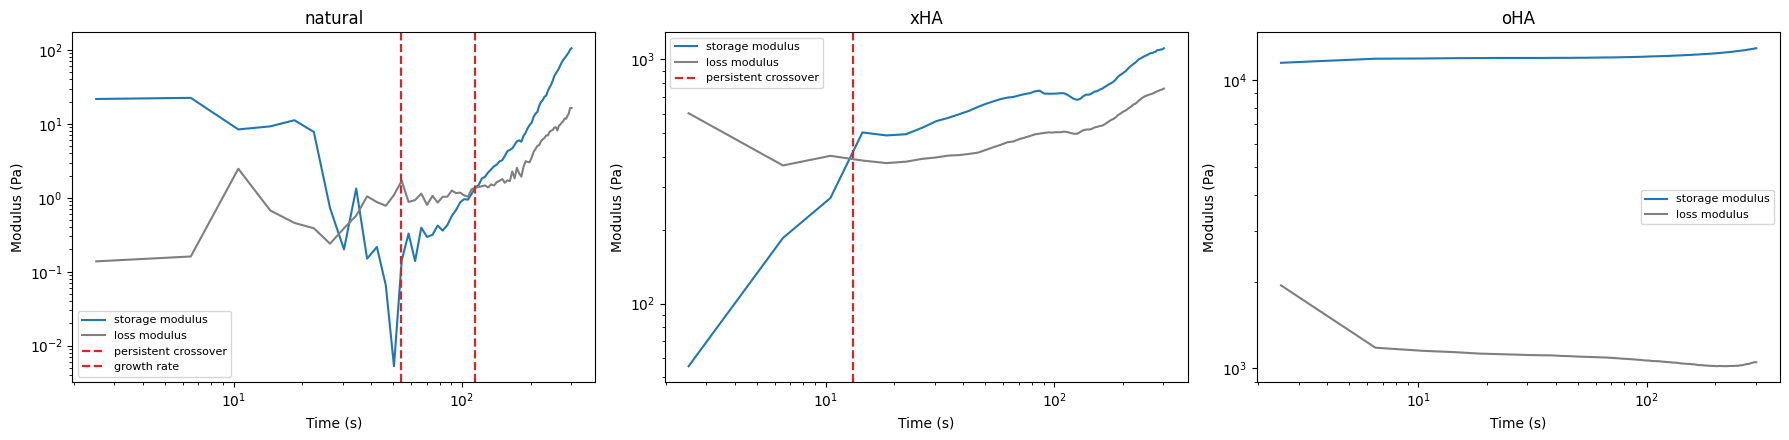

In [9]:
record_count = len(measurement_records)

if record_count > 0:

    figure_object, axis_array = plt.subplots(1, record_count,
                                             figsize=(6 * record_count, 4.5),
                                             squeeze=False)

    for record_index in range(record_count):

        record = measurement_records[record_index]
        axis_object = axis_array[0][record_index]

        time_values = np.asarray(record["time_seconds"], dtype=float)

        if record.get("storage_modulus") is not None:

            axis_object.loglog(time_values,
                               np.maximum(np.asarray(record["storage_modulus"],
                                                     dtype=float), 1e-6),
                               "-", color=COLOUR_PRIMARY, linewidth=1.5,
                               label="storage modulus")
            axis_object.loglog(time_values,
                               np.maximum(np.asarray(record["loss_modulus"],
                                                     dtype=float), 1e-6),
                               "-", color=COLOUR_NEUTRAL, linewidth=1.5,
                               label="loss modulus")
            axis_object.set_ylabel("Modulus (Pa)")
        else:
            axis_object.plot(time_values,
                             np.asarray(record["single_channel"], dtype=float),
                             "-", color=COLOUR_PRIMARY, linewidth=1.5,
                             label=record.get("channel_units", "signal"))
            axis_object.set_ylabel(record.get("channel_units", "signal"))

        for detector_name in record.get("results", {}):

            result = record["results"][detector_name]

            if result["verdict"] != "usable":
                continue

            axis_object.axvline(result["estimate"], color=COLOUR_SECONDARY,
                                linestyle="--", linewidth=1.6,
                                label=detector_name)

        axis_object.set_xlabel("Time (s)")
        axis_object.set_title(str(record["record_name"]))
        axis_object.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

## 9  Notes

**Verifying the notebook.** Run it unchanged against the included example. The natural sheep
blood record should give a persistent crossover at 114.21 s, against a published clot time of
117.1 s, an error of 2.5 percent. The oHA record should return nothing from the crossover,
correctly, because that clot formed before the recording began.

**Why the example loader splits its input.** The example file stacks two experiments in one
column, a time sweep followed by an amplitude sweep whose axis restarts. Section 3 detects this
and the loader acts on it, keeping the first block. Read as a single record the same file gives
98.6 s instead of 114.2, which is a fourteen percent error introduced entirely by the file
layout. Four of the thirteen datasets in the research notebook were stacked this way.

**The instrument noise floor.** The single most useful thing to supply. It is the smallest
modulus the instrument can resolve, in pascals, not a percentage. Without it the crossover
cannot reject a crossing that happens in the noise, which is how it failed on four of five real
gelations before the amendment was added.

**Detectors deliberately omitted.** Four of the seven detectors in the research notebook failed
on every real blood dataset: the Hill 5 half rise, the kernel changepoint, CUSUM, and the
unamended crossover. They are not included here.

**Sampling.** The extraction underlying this work stays within one percent of itself down to 4.2
samples per cycle of the highest frequency present, so acquisition rate is unlikely to be the
binding constraint. Coverage before and after the transition matters far more.